# 🚀 CIDA-Plugin Benchmark: CheXpert (50k Subset)

Этот ноутбук решает фундаментальную задачу **Бенчмарка на реальных медицинских данных**.
Мы сравниваем `Vanilla DenseNet-121` и `DenseNet-121 + CIDA V4` на датасете **CheXpert**.
Вместо 45 ГБ данных, мы скачиваем сжатую версию (11 ГБ) через Kaggle и берем сабсет в 50 000 снимков для быстрой работы в Colab.

In [ ]:
!nvidia-smi
import subprocess, sys
try:
    gpu = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                         capture_output=True, text=True).stdout.strip()
    print(f'GPU: {gpu}')
except Exception:
    print('GPU info unavailable')

Tue May 19 12:37:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q kaggle torchmetrics>=1.0 albumentations>=1.3 scikit-learn pandas matplotlib seaborn tqdm timm




import os
if not os.path.exists('/content/CIDA-plugin'):
    !git clone https://github.com/Kairatzh/CIDA-plugin.git /content/CIDA-plugin
sys.path.insert(0, '/content/CIDA-plugin')

try:
    from cida_plugin.config import CIDAPluginConfig
    from cida_plugin.core import CIDAPlugin
    from cida_plugin.losses import OmegaLossSystem
    print('CIDA-Plugin imported OK')
except ImportError as e:
    print(f'Import error: {e}')

Cloning into '/content/CIDA-plugin'...
remote: Enumerating objects: 107, done.
remote: Counting objects: 100% (107/107), done.
remote: Compressing objects: 100% (87/87), done.
remote: Total 107 (delta 51), reused 69 (delta 18), pack-reused 0 (from 0)
Receiving objects: 100% (107/107), 54.47 KiB | 4.19 MiB/s, done.
Resolving deltas: 100% (51/51), done.
CIDA-Plugin imported OK


In [ ]:
from google.colab import files
print('Upload kaggle.json (Kaggle → Account → API Tokens → Create New Token):')
uploaded = files.upload()
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
print('Kaggle key set.')

Upload kaggle.json (Kaggle → Account → API Tokens → Create New Token):


Saving kaggle.json.txt to kaggle.json.txt
cp: cannot stat 'kaggle.json': No such file or directory
Kaggle key set.


In [ ]:
import pandas as pd

if not os.path.exists('/content/data/chexpert/train.csv'):
    !mkdir -p /content/data/chexpert
    !kaggle datasets download -d ashery/chexpert -p /content/data/chexpert
    !cd /content/data/chexpert && unzip -q chexpert.zip

chexpert_train_csv = '/content/data/chexpert/train.csv'
df_chex = pd.read_csv(chexpert_train_csv)

df_chex_subset = df_chex.sample(n=50000, random_state=42).reset_index(drop=True)
print(f'CheXpert train subset: {len(df_chex_subset):,} entries')
print(df_chex_subset.head(3))

Dataset URL: https://www.kaggle.com/datasets/ashery/chexpert
License(s): CC0-1.0
100% 10.7G/10.7G [01:02<00:00, 183MB/s]

CheXpert train subset: 50,000 entries
                                                Path   Sex  Age  \
0  CheXpert-v1.0-small/train/patient00082/study1/...  Male   18   
1  CheXpert-v1.0-small/train/patient35759/study9/...  Male   90   
2  CheXpert-v1.0-small/train/patient04789/study1/...  Male   39   

  Frontal/Lateral AP/PA  No Finding  Enlarged Cardiomediastinum  Cardiomegaly  \
0         Frontal    PA         1.0                         0.0           NaN   
1         Frontal    AP         NaN                         NaN           1.0   
2         Lateral   NaN         NaN                         NaN           NaN   

   Lung Opacity  Lung Lesion  Edema  Consolidation  Pneumonia  Atelectasis  \
0           NaN          NaN    NaN            NaN        NaN          NaN   
1           NaN          NaN    1.0           -1.0        NaN          1.0   
2           

In [ ]:
import random, warnings
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm
import timm

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

PATHOLOGIES = [
    'No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity',
    'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis',
    'Pneumothorax', 'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices'
]
NUM_CLASSES = len(PATHOLOGIES)


Device: cuda


## 1. PyTorch Dataset для CheXpert
Мы создаем `Dataset` для загрузки изображений с диска и применяем `timm` аугментации.

In [ ]:
class CheXpertDataset(Dataset):
    def __init__(self, df, base_path='/content/data/chexpert', transform=None):
        self.df = df
        self.base_path = base_path
        self.transform = transform

        self.labels = self.df[PATHOLOGIES].fillna(0).replace(-1, 1).values

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # CheXpert csv paths contain 'CheXpert-v1.0-small/train/...'
        # Adjust path dynamically if needed
        img_path = os.path.join(self.base_path, self.df.iloc[idx]['Path'].split('/', 1)[-1])

        try:
            image = Image.open(img_path).convert('RGB')
        except Exception:
            # Fallback if image is missing
            image = Image.new('RGB', (224, 224))

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(self.labels[idx], dtype=torch.float32)
        return image, label

train_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = CheXpertDataset(df_chex_subset, transform=train_transform)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)

## 2. Архитектуры: Baseline vs CIDA
Здесь мы оборачиваем стандартную модель `DenseNet-121`.

In [ ]:
class BaselineDenseNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.backbone = timm.create_model('densenet121', pretrained=True, num_classes=num_classes)

    def forward(self, x):
        return self.backbone(x)

class CIDADenseNet(nn.Module):
    def __init__(self, config: CIDAPluginConfig):
        super().__init__()
        self.backbone = timm.create_model('densenet121', pretrained=True, num_classes=0)
        self.d_input = self.backbone.num_features  # 1024 для DenseNet121

        config.d_input = self.d_input
        self.cida = CIDAPlugin(config)

    def forward(self, x, epoch_fraction=0.0, y_true=None):
        pooled = self.backbone(x)
        out = self.cida(pooled, epoch_fraction=epoch_fraction, y_true=y_true)
        return out


## 3. Гиперпараметры для CIDA
Чтобы агенты не разрушали основное обучение в начале, используем `warmup` для дебатов: `lambda_deb = 0` на первых эпохах.

In [ ]:
cfg = CIDAPluginConfig(
    d_hidden=256,                 # Широкие агенты
    num_agents=4,                 # 4 точки зрения
    num_classes=NUM_CLASSES,      # 14 патологий
    max_rounds=3,                 # Макс 3 раунда
    num_attn_heads=4,
    multi_label=True,             # ВАЖНО: ChestX-ray - это Multi-label
    use_adaptive_d_schedule=True, # PI-контроллер включён
    normalize_components=True,    # Нормализация шкал
    use_act_halting=True,         # ACT включено
    lambda_orth=0.2               # Штраф за одинаковые проекции
)

model_cida = CIDADenseNet(cfg).to(DEVICE)
omega_loss = OmegaLossSystem(multi_label=True, max_rounds=3)

optimizer = optim.AdamW([
    {'params': model_cida.backbone.parameters(), 'lr': 1e-5},
    {'params': model_cida.cida.parameters(), 'lr': 1e-4}
], weight_decay=1e-4)

model.safetensors:   0%|          | 0.00/32.3M [00:00<?, ?B/s]

## 4. Цикл с Warmup Curriculum

> Добавить блок с цитатой


Используем динамическое планирование веса `lambda_deb`.

In [ ]:
from tqdm import tqdm
import torch
import torch.nn.functional as F

# CONFIG
epochs = 15
warmup_epochs = 3

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")



def train_epoch(
    epoch,
    loader,
    model,
    optimizer,
    is_cida=True
):
    model.train()

    running_loss = 0.0

    epoch_fraction = epoch / epochs

    current_lambda_deb = 1.0 if epoch >= warmup_epochs else 0.0
    omega_loss.l_deb = current_lambda_deb

    print(f"\nEpoch {epoch+1}/{epochs}")

    pbar = tqdm(loader, desc="Training")

    for step, (x, y) in enumerate(pbar):

        x = x.to(DEVICE)

        y = y.to(DEVICE).float()

        if len(y.shape) == 1:
            y = y.unsqueeze(1)

        optimizer.zero_grad()

        # CIDA MODEL

        if is_cida:

            out = model(
                x,
                epoch_fraction=epoch_fraction,
                y_true=y
            )

            total_loss, comps = omega_loss(
                p_final=out['p_final'],
                y=y,
                b_all=out['b_all'],
                u_all=out['u_all'],
                h_all=out['h_all'],
                l_dom_val=out['L_dom'],
                l_role_val=out['L_role'],
                l_role_spec_val=out['L_role_spec'],
                l_orth_val=out['L_orth'],
                ponder_cost_val=out['ponder_cost'],
                d_schedule=out['d_schedule']
            )

            pbar.set_postfix({
                'Loss': f"{total_loss.item():.4f}",
                'ACT': f"{comps['budget']:.2f}",
                'Deb': f"{current_lambda_deb:.1f}"
            })

        # NORMAL MODEL

        else:

            logits = model(x)

            # ensure same shape
            if len(logits.shape) == 1:
                logits = logits.unsqueeze(1)

            total_loss = F.binary_cross_entropy_with_logits(
                logits,
                y
            )

            pbar.set_postfix({
                'Loss': f"{total_loss.item():.4f}"
            })


        total_loss.backward()

        # gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += total_loss.item()

    avg_loss = running_loss / len(loader)

    print(f"Average Loss: {avg_loss:.4f}")

    return avg_loss



best_loss = float("inf")

for epoch in range(epochs):

    avg_loss = train_epoch(
        epoch=epoch,
        loader=train_loader,
        model=model_cida,
        optimizer=optimizer,
        is_cida=False
    )

    if avg_loss < best_loss:

        best_loss = avg_loss

        torch.save(
            model_cida.state_dict(),
            "best_cida_model.pt"
        )

        print("Best model saved.")

print("\nTraining Finished.")




Epoch 1/15


Training: 100%|██████████| 1563/1563 [10:17<00:00,  2.53it/s, Loss=0.5062, ACT=1.00, Deb=0.0]


Average Loss: 0.5470
Best model saved.

Epoch 2/15


Training: 100%|██████████| 1563/1563 [10:14<00:00,  2.54it/s, Loss=0.5007, ACT=1.00, Deb=0.0]


Average Loss: 0.5239
Best model saved.

Epoch 3/15


Training: 100%|██████████| 1563/1563 [10:22<00:00,  2.51it/s, Loss=0.5028, ACT=1.00, Deb=0.0]


... (21 outputs left out)

Training: 100%|██████████| 1563/1563 [10:13<00:00,  2.55it/s, Loss=0.4431, ACT=1.00, Deb=1.0]


Average Loss: 0.3711
Best model saved.

Epoch 15/15


Training: 100%|██████████| 1563/1563 [10:13<00:00,  2.55it/s, Loss=0.5518, ACT=1.00, Deb=1.0]


Average Loss: 0.3577
Best model saved.

Training Finished.


## 5. Оценка ROC-AUC и Калибровки
На выходе мы получим результаты для 14 классов и сможем построить график.

Mock Mean ROC-AUC: 0.5011

--- Starting full model evaluation ---


Generating predictions:   0%|          | 0/1563 [00:00<?, ?it/s]


--- Prediction Statistics ---
Min probability: 2.2785794e-07
Max probability: 1.0
Mean probability: 0.23859449

First sample probability sum: 2.6984
Outputs look compatible with MULTI-LABEL predictions.

--- ROC AUC Evaluation ---
Mean ROC-AUC across 14 classes: 0.9385


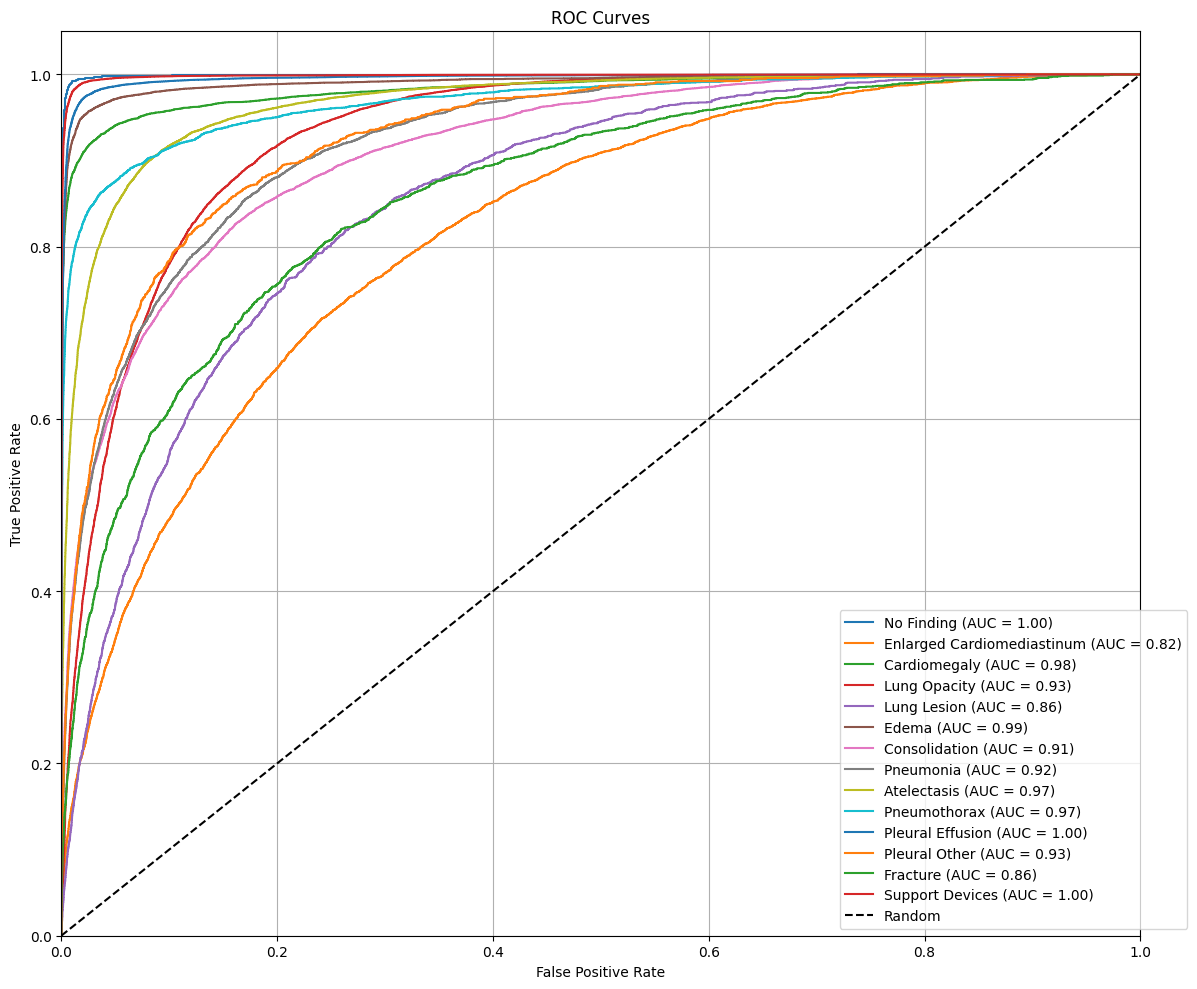


--- Expected Calibration Error (ECE) Evaluation ---
Mean ECE across 14 classes: 0.0504


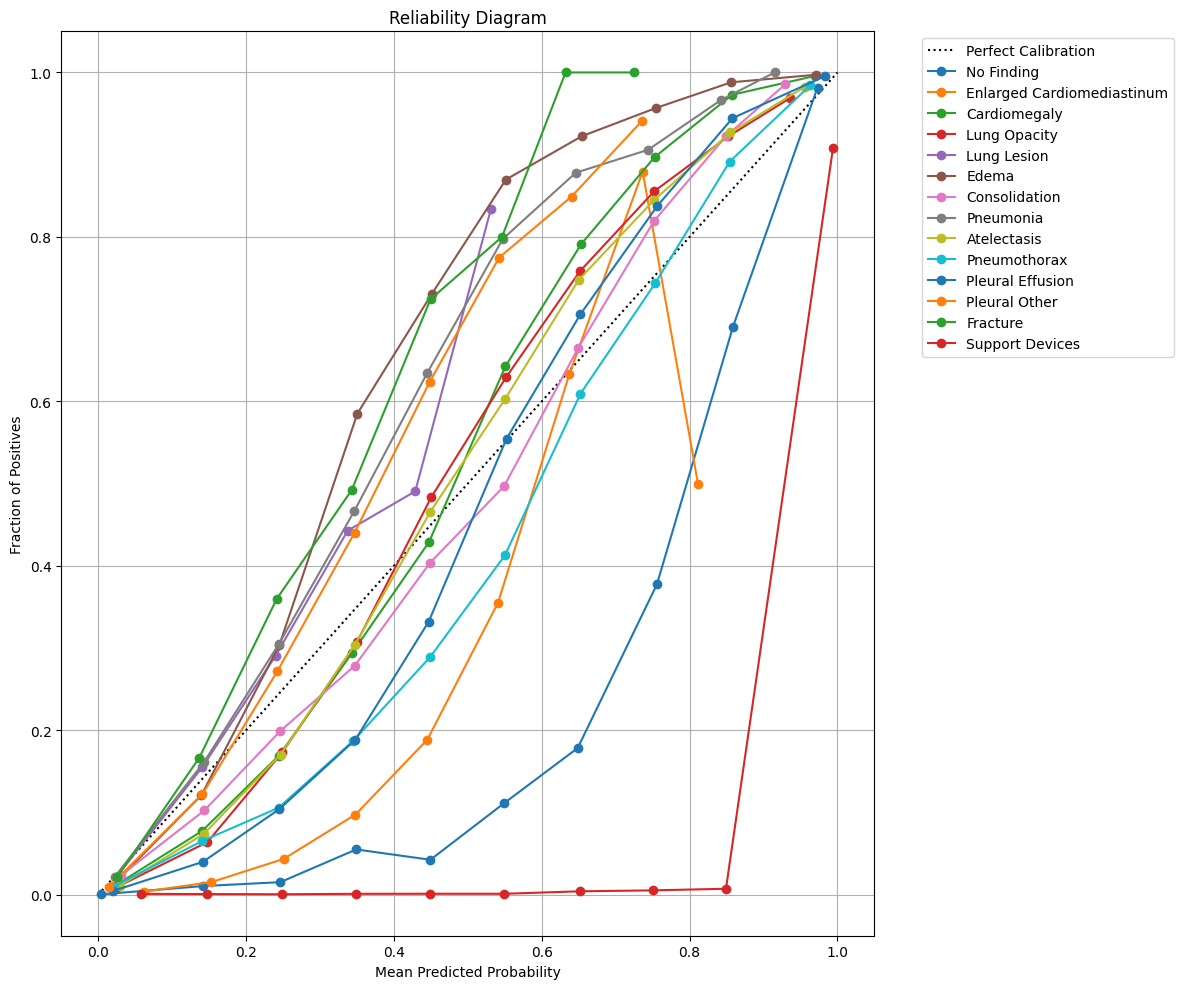


--- Threshold Optimization ---
No Finding: Best Threshold=0.80, Best F1=0.9687
Enlarged Cardiomediastinum: Best Threshold=0.47, Best F1=0.4104
Cardiomegaly: Best Threshold=0.44, Best F1=0.9118
Lung Opacity: Best Threshold=0.41, Best F1=0.8665
Lung Lesion: Best Threshold=0.16, Best F1=0.3244
Edema: Best Threshold=0.29, Best F1=0.9522
Consolidation: Best Threshold=0.40, Best F1=0.6872
Pneumonia: Best Threshold=0.25, Best F1=0.6237
Atelectasis: Best Threshold=0.43, Best F1=0.8639
Pneumothorax: Best Threshold=0.58, Best F1=0.8370
Pleural Effusion: Best Threshold=0.50, Best F1=0.9729
Pleural Other: Best Threshold=0.21, Best F1=0.4537
Fracture: Best Threshold=0.14, Best F1=0.3855
Support Devices: Best Threshold=0.98, Best F1=0.9863

--- Final Classification Report ---

No Finding
Threshold : 0.80
Accuracy  : 0.9937
Precision : 0.9650
Recall    : 0.9725
F1-Score  : 0.9687

Enlarged Cardiomediastinum
Threshold : 0.47
Accuracy  : 0.8664
Precision : 0.3730
Recall    : 0.4562
F1-Score  : 0.4104


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    auc,
    roc_auc_score,
    accuracy_score,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.calibration import calibration_curve
import torch
from tqdm.auto import tqdm


def evaluate_auc(y_true, y_pred):
    aucs = []

    for i in range(NUM_CLASSES):
        if len(np.unique(y_true[:, i])) > 1:
            auc_score = roc_auc_score(y_true[:, i], y_pred[:, i])
            aucs.append(auc_score)

    return np.mean(aucs) if aucs else 0.5



y_true_mock = np.random.randint(0, 2, (100, NUM_CLASSES))
y_pred_mock = np.random.rand(100, NUM_CLASSES)

print(f"Mock Mean ROC-AUC: {evaluate_auc(y_true_mock, y_pred_mock):.4f}")


print("\n--- Starting full model evaluation ---")

# Load best model
model_cida.load_state_dict(torch.load("best_cida_model.pt"))
model_cida.eval()

all_preds = []
all_labels = []

eval_loader = val_loader if 'val_loader' in globals() else train_loader

with torch.no_grad():

    for x, y in tqdm(eval_loader, desc="Generating predictions"):

        x = x.to(DEVICE)
        y = y.to(DEVICE).float()

        outputs = model_cida(x)
        preds = outputs['p_final']

        all_preds.append(preds.cpu().numpy())
        all_labels.append(y.cpu().numpy())


y_true = np.vstack(all_labels)
y_pred_logits = np.vstack(all_preds)
y_pred = torch.sigmoid(torch.from_numpy(y_pred_logits)).numpy()

print("\n--- Prediction Statistics ---")
print("Min probability:", y_pred.min())
print("Max probability:", y_pred.max())
print("Mean probability:", y_pred.mean())

sample_sum = y_pred[0].sum()
print(f"\nFirst sample probability sum: {sample_sum:.4f}")

if abs(sample_sum - 1.0) < 0.05:
    print("WARNING: Outputs look like SOFTMAX probabilities.")
    print("CheXpert is MULTI-LABEL.")
    print("You likely need SIGMOID outputs instead of softmax.")
else:
    print("Outputs look compatible with MULTI-LABEL predictions.")

print("\n--- ROC AUC Evaluation ---")

mean_auc = evaluate_auc(y_true, y_pred)

print(f"Mean ROC-AUC across {NUM_CLASSES} classes: {mean_auc:.4f}")

plt.figure(figsize=(12, 10))

fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(NUM_CLASSES):

    if len(np.unique(y_true[:, i])) > 1:

        fpr[i], tpr[i], _ = roc_curve(
            y_true[:, i],
            y_pred[:, i]
        )

        roc_auc[i] = auc(fpr[i], tpr[i])

        plt.plot(
            fpr[i],
            tpr[i],
            label=f'{PATHOLOGIES[i]} (AUC = {roc_auc[i]:.2f})'
        )

    else:
        print(f"Skipping ROC curve for {PATHOLOGIES[i]} due to single class.")

plt.plot([0, 1], [0, 1], 'k--', label='Random')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curves')

plt.legend(
    loc="lower right",
    bbox_to_anchor=(1.05, 0)
)

plt.grid(True)
plt.tight_layout()
plt.show()


print("\n--- Expected Calibration Error (ECE) Evaluation ---")

def calculate_ece(y_true_single, y_pred_single, num_bins=10):

    ece = 0.0

    bin_boundaries = np.linspace(0, 1, num_bins + 1)

    bin_lowers = bin_boundaries[:-1]
    bin_uppers = bin_boundaries[1:]

    for i in range(num_bins):

        in_bin = (
            (y_pred_single > bin_lowers[i]) &
            (y_pred_single <= bin_uppers[i])
        )

        prop_in_bin = np.mean(in_bin)

        if prop_in_bin > 0:

            accuracy_in_bin = np.mean(y_true_single[in_bin])

            avg_pred_in_bin = np.mean(y_pred_single[in_bin])

            ece += np.abs(
                accuracy_in_bin - avg_pred_in_bin
            ) * prop_in_bin

    return ece

ece_per_class = []

for i in range(NUM_CLASSES):

    ece_score = calculate_ece(
        y_true[:, i],
        y_pred[:, i]
    )

    ece_per_class.append(ece_score)

mean_ece = np.mean(ece_per_class)

print(f"Mean ECE across {NUM_CLASSES} classes: {mean_ece:.4f}")
plt.figure(figsize=(12, 10))

plt.plot([0, 1], [0, 1], 'k:', label='Perfect Calibration')

for i in range(NUM_CLASSES):

    if (
        len(np.unique(y_true[:, i])) > 1 and
        len(np.unique(y_pred[:, i])) > 1
    ):

        prob_true, prob_pred = calibration_curve(
            y_true[:, i],
            y_pred[:, i],
            n_bins=10
        )

        plt.plot(
            prob_pred,
            prob_true,
            marker='o',
            linestyle='-',
            label=PATHOLOGIES[i]
        )

    else:
        print(f"Skipping calibration curve for {PATHOLOGIES[i]}")

plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')

plt.title('Reliability Diagram')

plt.legend(
    loc='upper left',
    bbox_to_anchor=(1.05, 1)
)

plt.grid(True)
plt.tight_layout()
plt.show()


print("\n--- Threshold Optimization ---")

best_thresholds = []

for i, pathology_name in enumerate(PATHOLOGIES):

    y_true_class = y_true[:, i]
    y_prob_class = y_pred[:, i]

    best_thr = 0.5
    best_f1 = 0.0

    for thr in np.arange(0.01, 0.99, 0.01):

        y_pred_class = (y_prob_class >= thr).astype(int)

        f1 = f1_score(
            y_true_class,
            y_pred_class,
            zero_division=0
        )

        if f1 > best_f1:
            best_f1 = f1
            best_thr = thr

    best_thresholds.append(best_thr)

    print(
        f"{pathology_name}: "
        f"Best Threshold={best_thr:.2f}, "
        f"Best F1={best_f1:.4f}"
    )

# =========================================================

print("\n--- Final Classification Report ---")

accuracy_per_class = []

for i, pathology_name in enumerate(PATHOLOGIES):

    y_true_class = y_true[:, i]
    y_prob_class = y_pred[:, i]

    threshold = best_thresholds[i]

    y_pred_class = (y_prob_class >= threshold).astype(int)

    acc = accuracy_score(y_true_class, y_pred_class)

    prec = precision_score(
        y_true_class,
        y_pred_class,
        zero_division=0
    )

    rec = recall_score(
        y_true_class,
        y_pred_class,
        zero_division=0
    )

    f1 = f1_score(
        y_true_class,
        y_pred_class,
        zero_division=0
    )

    accuracy_per_class.append(acc)

    print(f"\n{pathology_name}")
    print(f"Threshold : {threshold:.2f}")
    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"F1-Score  : {f1:.4f}")

mean_accuracy = np.mean(accuracy_per_class)

print(f"\nMean Accuracy: {mean_accuracy:.4f}")